# 11. Sensitivity to the duration of the strike window

The spectral features of each strike (notebook 01) are computed over a window of **0.4 s** starting 5 ms before the
strike maximum. The window must be much longer than the contact of the hammer (a few milliseconds), to describe the
resonance of the stone, and shorter than the spacing between strikes (≥ 0.86 s, median 1.18 s). Within that range, do
the conclusions depend on the chosen duration?

The features (centroid, bandwidth, MFCC 0–12) are recomputed with windows of **0.1, 0.2, 0.3, 0.4, 0.6 and 0.8 s**,
same start and same strikes of the characterisation set (notebook 01, section 1.3), and for each one the figures of
the article are recomputed:

| Notebook | Figure |
|---|---|
| 05 | Kruskal–Wallis ε² (6 features); variance share of the zone and of the recording (mixed model, no bootstrap); PERMANOVA pseudo-F and R² (no permutations) |
| 07 | random-forest accuracy leaving one recording out and with a random 70/30 split |
| 04 | Spearman correlation between the distance to the edge and the zone-mean bandwidth and centroid |

**Inputs:** `intermediate/strikes.csv` (01), `intermediate/strikes_with_acceleration.csv` (02),
`tables/t04_zone_coordinates.csv`, `tables/t07_validation.csv`. **Outputs:** `tables/t11_window_sensitivity.csv`,
`figures/fig11_window_sensitivity.png`.

In [1]:
import sys, warnings
from pathlib import Path
sys.path.insert(0, str(Path.cwd().parent / "src"))   # folder with config.py
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import config as C
warnings.filterwarnings("ignore", category=FutureWarning)
plt.rcParams.update({"figure.dpi": 110, "axes.grid": True, "grid.alpha": 0.4})
pd.set_option("display.precision", 2)

import librosa
from scipy import signal, stats
from scipy.io import wavfile
from scipy.spatial.distance import pdist, squareform
import statsmodels.formula.api as smf
from sklearn.preprocessing import StandardScaler
from sklearn.ensemble import RandomForestClassifier
from sklearn.model_selection import LeaveOneGroupOut, cross_val_predict, train_test_split
from sklearn.metrics import accuracy_score
warnings.filterwarnings("ignore")
FS = C.FS
WINDOWS = [0.1, 0.2, 0.3, 0.4, 0.6, 0.8]
VARS = ["spectral_centroid", "spectral_bandwidth", "mfcc_0", "mfcc_1", "mfcc_2", "mfcc_3"]   # those of notebook 05

## 11.1 Spectral features with each window

In [2]:
G = pd.read_csv(C.INTERMEDIATE / "strikes.csv")
G = G[G.set == "characterisation"].reset_index(drop=True)   # characterisation set
b5, a5 = signal.butter(C.FILTER_ORDER, C.HIGHPASS_HZ / (FS / 2), "high")
def features(y):                               # as in notebook 01
    y = y.astype(np.float64)
    d = {"spectral_centroid": np.mean(librosa.feature.spectral_centroid(y=y, sr=FS)),
         "spectral_bandwidth": np.mean(librosa.feature.spectral_bandwidth(y=y, sr=FS))}
    for i, v in enumerate(librosa.feature.mfcc(y=y, sr=FS, n_mfcc=C.N_MFCC).mean(axis=1)):
        d[f"mfcc_{i}"] = v
    return d
rows = []
for w, gw in G.groupby("file"):
    _, x = wavfile.read(C.AUDIO / w); xf = signal.filtfilt(b5, a5, x.astype(np.float32).mean(axis=1))
    for r in gw.itertuples():
        a = r.i_peak - int(C.PRE_PEAK * FS)
        for L in WINDOWS:
            rows.append({"window_s": L, "zone": r.zone, "strike": r.strike, "file": w,
                         **features(xf[a:a + int(round(L * FS))])})
FV = pd.DataFrame(rows)
ref = pd.read_csv(C.INTERMEDIATE / "features.csv")
m = FV[FV.window_s == 0.4].merge(ref, on=["zone", "strike"], suffixes=("", "_ref"))
assert max(np.abs(m[c] - m[c + "_ref"]).max() for c in C.RF_FEATURES) < 1e-6, "0.4 s does not reproduce notebook 01"
print(f"{len(G)} strikes × {len(WINDOWS)} windows; with 0.4 s the features of notebook 01 are reproduced")

371 strikes × 6 windows; with 0.4 s the features of notebook 01 are reproduced


## 11.2 Figures of the article with each window

In [3]:
acc = pd.read_csv(C.INTERMEDIATE / "strikes_with_acceleration.csv")[["zone", "strike", "acc_peak"]]
geo = pd.read_csv(C.TABLES / "t04_zone_coordinates.csv")[["zone", "edge_distance_m"]]
def components(df, c):                         # mixed model of notebook 05
    m = smf.mixedlm(f"{c} ~ log_acc", df, groups=df["zone"], re_formula="1",
                    vc_formula={"file": "0 + file"}).fit(reml=True)
    vz, vr, ve = float(m.cov_re.iloc[0, 0]), float(m.vcomp[0]), float(m.scale)
    return vz / (vz + vr + ve), vr / (vz + vr + ve)
def permanova(d):                              # pseudo-F and R² of notebook 05
    X = StandardScaler().fit_transform(d[VARS]); D2 = squareform(pdist(X)) ** 2; g = d.zone.values; n = len(g)
    labs = np.unique(g); sst = D2.sum() / (2 * n)
    ssw = sum(D2[np.ix_(g == l, g == l)].sum() / (2 * (g == l).sum()) for l in labs)
    return ((sst - ssw) / (len(labs) - 1)) / (ssw / (n - len(labs))), 1 - ssw / sst
rf = lambda: RandomForestClassifier(random_state=C.SEED)
res = []
for L, d in FV.groupby("window_s"):
    d = d.reset_index(drop=True)
    eps = [stats.kruskal(*[g[c].values for _, g in d.groupby("zone")])[0] / (len(d) - 1) for c in VARS]
    dm = d.merge(acc, on=["zone", "strike"]); dm["log_acc"] = np.log10(dm.acc_peak.clip(lower=0.01))
    dm = dm.dropna(subset=["log_acc"]).reset_index(drop=True)
    cz = np.array([components(dm, c) for c in VARS])
    Fp, R2 = permanova(d)
    X, y = d[C.RF_FEATURES], d.zone
    yp = cross_val_predict(rf(), X, y, groups=d.file, cv=LeaveOneGroupOut(), n_jobs=-1)
    Xa, Xb, ya, yb = train_test_split(X, y, test_size=0.3, random_state=C.SEED, stratify=y)
    zc = d.groupby("zone")[["spectral_centroid", "spectral_bandwidth"]].mean().reset_index().merge(geo, on="zone")
    rb, pb = stats.spearmanr(zc.edge_distance_m, zc.spectral_bandwidth); rc, pc = stats.spearmanr(zc.edge_distance_m, zc.spectral_centroid)
    res.append({"window_s": L, "epsilon2_min": min(eps), "epsilon2_max": max(eps),
                "zone_var_min": cz[:, 0].min(), "zone_var_max": cz[:, 0].max(), "zone_var_bandwidth": cz[1, 0],
                "recording_var_min": cz[:, 1].min(), "recording_var_max": cz[:, 1].max(),
                "permanova_F": Fp, "permanova_R2": R2,
                "rf_leave_one_recording_out": (yp == y.values).mean(),
                "rf_random_70_30": accuracy_score(yb, rf().fit(Xa, ya).predict(Xb)),
                "rho_edge_bandwidth": rb, "p_edge_bandwidth": pb, "rho_edge_centroid": rc, "p_edge_centroid": pc,
                "centroid_median_Hz": d.spectral_centroid.median(), "bandwidth_median_Hz": d.spectral_bandwidth.median()})
S = pd.DataFrame(res); S.to_csv(C.TABLES / "t11_window_sensitivity.csv", index=False)
S.set_index("window_s").T.round(3)

window_s,0.1,0.2,0.3,0.4,0.6,0.8
epsilon2_min,0.40,0.39,0.41,0.39,3.77e-01,3.60e-01
epsilon2_max,0.54,0.59,0.62,0.64,6.45e-01,6.40e-01
zone_var_min,0.26,0.20,0.23,0.23,2.13e-01,1.75e-01
zone_var_max,0.45,0.54,0.59,0.62,6.38e-01,6.30e-01
zone_var_bandwidth,0.39,0.38,0.47,0.48,4.42e-01,3.59e-01
recording_var_min,0.28,0.24,0.22,0.19,1.64e-01,1.77e-01
recording_var_max,0.41,0.45,0.45,0.43,4.19e-01,4.07e-01
permanova_F,13.29,13.53,15.21,15.12,1.35e+01,1.15e+01
permanova_R2,0.47,0.47,0.50,0.50,4.72e-01,4.33e-01
rf_leave_one_recording_out,0.52,0.61,0.66,0.65,6.20e-01,6.01e-01


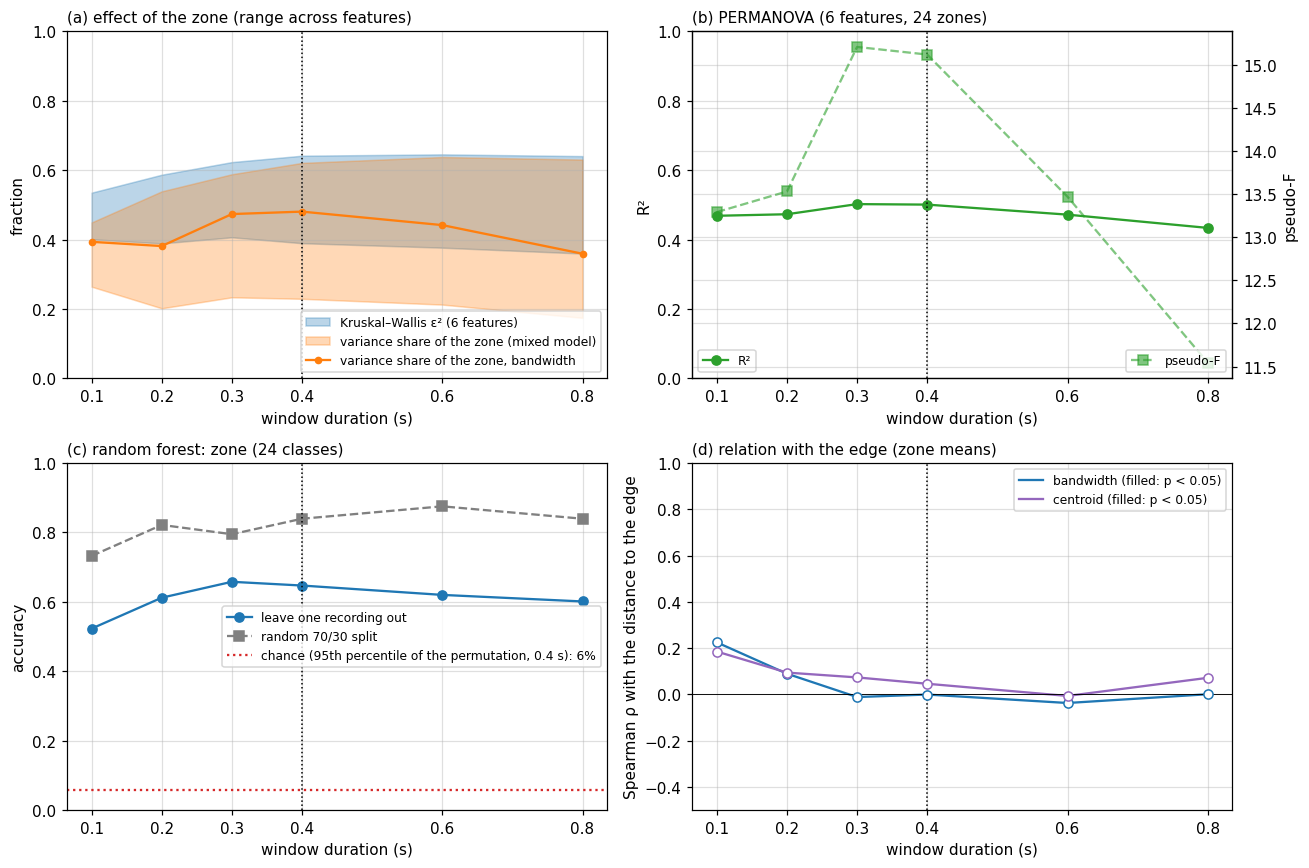

In [4]:
chance = pd.read_csv(C.TABLES / "t07_validation.csv").chance_p95.iloc[0]
L = S.window_s; fig, ax = plt.subplots(2, 2, figsize=(12, 8)); ax = ax.ravel()
ax[0].fill_between(L, S.epsilon2_min, S.epsilon2_max, alpha=.3, color="C0", label="Kruskal–Wallis ε² (6 features)")
ax[0].fill_between(L, S.zone_var_min, S.zone_var_max, alpha=.3, color="C1", label="variance share of the zone (mixed model)")
ax[0].plot(L, S.zone_var_bandwidth, "o-", color="C1", ms=4, label="variance share of the zone, bandwidth")
ax[0].set_ylim(0, 1); ax[0].set_ylabel("fraction"); ax[0].set_title("(a) effect of the zone (range across features)", loc="left", fontsize=10)
ax[1].plot(L, S.permanova_R2, "o-", color="C2", label="R²"); a2 = ax[1].twinx()
a2.plot(L, S.permanova_F, "s--", color="C2", alpha=.6, label="pseudo-F"); a2.set_ylabel("pseudo-F")
ax[1].set_ylim(0, 1); ax[1].set_ylabel("R²"); ax[1].set_title("(b) PERMANOVA (6 features, 24 zones)", loc="left", fontsize=10)
ax[1].legend(loc="lower left", fontsize=8); a2.legend(loc="lower right", fontsize=8)
ax[2].plot(L, S.rf_leave_one_recording_out, "o-", label="leave one recording out")
ax[2].plot(L, S.rf_random_70_30, "s--", color="0.5", label="random 70/30 split")
ax[2].axhline(chance, color="C3", ls=":", label=f"chance (95th percentile of the permutation, 0.4 s): {chance:.0%}")
ax[2].set_ylim(0, 1); ax[2].set_ylabel("accuracy"); ax[2].set_title("(c) random forest: zone (24 classes)", loc="left", fontsize=10)
for c, name, col in [("bandwidth", "bandwidth", "C0"), ("centroid", "centroid", "C4")]:
    sig_ = S[f"p_edge_{c}"] < 0.05
    ax[3].plot(L, S[f"rho_edge_{c}"], "-", color=col, label=f"{name} (filled: p < 0.05)")
    ax[3].scatter(L[sig_], S[f"rho_edge_{c}"][sig_], color=col, zorder=3); ax[3].scatter(L[~sig_], S[f"rho_edge_{c}"][~sig_], facecolor="w", edgecolor=col, zorder=3)
ax[3].axhline(0, color="k", lw=.6); ax[3].set_ylim(-0.5, 1); ax[3].set_ylabel("Spearman ρ with the distance to the edge")
ax[3].set_title("(d) relation with the edge (zone means)", loc="left", fontsize=10)
for a in ax:
    a.axvline(0.4, color="k", ls=":", lw=1); a.set_xticks(WINDOWS); a.set_xlabel("window duration (s)")
ax[0].legend(fontsize=8, loc="lower right"); ax[2].legend(fontsize=8, loc="center right"); ax[3].legend(fontsize=8, loc="upper right")
plt.tight_layout(); plt.savefig(C.FIGURES / "fig11_window_sensitivity.png", dpi=150, bbox_inches="tight"); plt.show()

## Conclusion

With the strikes of the characterisation set:

* **Between 0.2 and 0.8 s the conclusions do not change:** the zone is the main source of variation (ε² 0.36–0.65;
  zone 18–64 % of the variance depending on the feature), PERMANOVA gives R² 0.43–0.50, the leave-one-recording-out
  classifier is right in 60–66 % of the strikes (chance with 0.4 s: median 3 %, 95th percentile 6 %) and **no feature
  is related to the distance to the edge** with any window (|ρ| ≤ 0.23, p ≥ 0.29).
* **0.4 s is among the windows that best separate the zones:** PERMANOVA and the classifier are highest with 0.3–0.4 s
  (R² 0.50; 65–66 %).
* **Very short windows (0.1 s)** are dominated by the attack of the hammer (median centroid 2980 Hz against 1650 Hz with
  0.4 s) and the classifier accuracy drops (52 %).
* **Long windows (0.6–0.8 s)** include more of the decay: the effect of the zone decreases somewhat (R² 0.43 with 0.8 s).